In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)

transform = transforms.ToTensor()
train_ds = datasets.MNIST("data", train=True, download=True, transform=transform)
test_ds = datasets.MNIST("data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=1000, shuffle=False)

# 784 -> 256 -> 10. Last layer is the linear probe (untouched by disentanglement).
hidden = 256
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, hidden),
    nn.ReLU(),
    nn.Linear(hidden, 10),
)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

train_losses = []
val_losses = []

n_epochs = 10
for epoch in range(1, n_epochs + 1):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    train_loss = running_loss / len(train_ds)

    model.eval()
    correct = 0
    val_running_loss = 0.0
    with torch.no_grad():
        for images, labels in test_loader:
            logits = model(images)
            val_running_loss += criterion(logits, labels).item() * images.size(0)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
    val_loss = val_running_loss / len(test_ds)
    test_acc = correct / len(test_ds)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    print(f"epoch {epoch:2d}  train_loss {train_loss:.4f}  val_loss {val_loss:.4f}  test_acc {test_acc:.4f}")

epoch  1  train_loss 0.4354  val_loss 0.2480  test_acc 0.9303
epoch  2  train_loss 0.2186  val_loss 0.1748  test_acc 0.9486
epoch  3  train_loss 0.1627  val_loss 0.1513  test_acc 0.9564
epoch  4  train_loss 0.1291  val_loss 0.1169  test_acc 0.9655
epoch  5  train_loss 0.1069  val_loss 0.1037  test_acc 0.9696
epoch  6  train_loss 0.0907  val_loss 0.0936  test_acc 0.9725
epoch  7  train_loss 0.0791  val_loss 0.0932  test_acc 0.9720
epoch  8  train_loss 0.0692  val_loss 0.0813  test_acc 0.9747
epoch  9  train_loss 0.0613  val_loss 0.0773  test_acc 0.9757
epoch 10  train_loss 0.0552  val_loss 0.0778  test_acc 0.9772


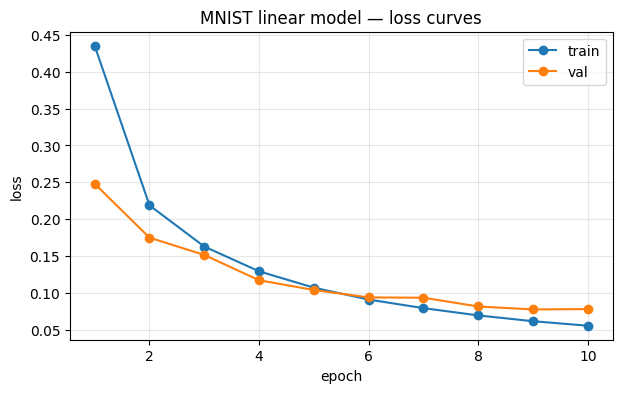

In [2]:
import matplotlib.pyplot as plt

epochs = range(1, n_epochs + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, train_losses, marker="o", label="train")
plt.plot(epochs, val_losses, marker="o", label="val")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("MNIST linear model — loss curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [3]:
import sys, types
from pathlib import Path
from unittest.mock import MagicMock

# The tensor_disentanglement_code package was carved out of an RL repo, so
# disentanglement_base.py imports a few modules that don't exist here. Stub
# them — we only call disentangle_matrix_via_reshape, which doesn't touch them.
disent_root = Path("tensor_disentanglement_code").resolve()
if str(disent_root) not in sys.path:
    sys.path.insert(0, str(disent_root))
for name in ("classes.rl_models", "utils.evals", "visualize", "visualize.disentangle", "gymnasium"):
    sys.modules.setdefault(name, MagicMock())

import importlib
import tensor_disentanglement_code.disentanglement_base as DB
importlib.reload(DB)

<module 'tensor_disentanglement_code.disentanglement_base' from '/Users/leonardevers/LLM_Sem/reward-density-quality/src/tensor_disentanglement_code/disentanglement_base.py'>

In [4]:
import copy

# Hidden-layer weight: shape (256, 784). Last layer (the probe) is left alone.
W = model[1].weight.detach().clone()
print(f"W shape: {tuple(W.shape)}")

result = DB.disentangle_matrix_via_reshape(
    W,
    steps=1000,
    learning_rate=0.05,
    seed=0,
    optimizer_type="adam_lie",
    rank_selection="fixed_heuristic",
    rank_fraction=0.1,
    log_prefix="W1",
    log_every=100,
)
inner = result.inner
Q = inner.best_q                                            # (256, 256) orthogonal, float64
shape4d = result.tensor_shape_4d
shape_tuple = (shape4d.left_outer, shape4d.left_inner, shape4d.right_outer, shape4d.right_inner)
keep_rank = inner.keep_rank
print(f"4D shape: {shape_tuple}  keep_rank: {keep_rank}")
print(f"entropy        {inner.initial_stats.entropy:.4f} -> {inner.best_stats.entropy:.4f}")
print(f"effective rank {inner.initial_stats.effective_rank:.2f} -> {inner.best_stats.effective_rank:.2f}")

# Truncate Q @ W to rank keep_rank in the disentangled matricization, then undo Q.
W64 = W.to(torch.float64)
QW = Q @ W64
permuted = DB._apply_A(QW, shape_tuple)                     # (448, 448)
U, S, Vh = torch.linalg.svd(permuted, full_matrices=False)
S_trunc = S.clone()
S_trunc[keep_rank:] = 0
permuted_trunc = (U * S_trunc) @ Vh
QW_trunc = DB._apply_A_inv(permuted_trunc, shape_tuple)
W_prime = (Q.transpose(-1, -2) @ QW_trunc).to(W.dtype)

rel_err = float((W - W_prime).norm() / W.norm())
print(f"||W - W'||_F / ||W||_F = {rel_err:.4f}")

# Frankenstein: same model, layer-1 weight swapped for W'. Eval.
model_frank = copy.deepcopy(model)
with torch.no_grad():
    model_frank[1].weight.copy_(W_prime)
model_frank.eval()
correct = 0
loss_sum = 0.0
with torch.no_grad():
    for images, labels in test_loader:
        logits = model_frank(images)
        loss_sum += criterion(logits, labels).item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
print(f"frankenstein  test_loss {loss_sum/len(test_ds):.4f}  test_acc {correct/len(test_ds):.4f}")

W shape: (256, 784)
[W1]step=0000 cost=8.918421e+01 entropy=5.050590 effective_rank=156.1146
[W1]step=0100 cost=4.301200e+01 entropy=4.389900 effective_rank=80.6324
[W1]step=0200 cost=3.997384e+01 entropy=4.323519 effective_rank=75.4537
[W1]step=0300 cost=3.871001e+01 entropy=4.291717 effective_rank=73.0919
[W1]step=0400 cost=3.805484e+01 entropy=4.276935 effective_rank=72.0194
[W1]step=0500 cost=3.742833e+01 entropy=4.261852 effective_rank=70.9412
[W1]step=0600 cost=3.754846e+01 entropy=4.262180 effective_rank=70.9645
[W1]step=0700 cost=3.697810e+01 entropy=4.249654 effective_rank=70.0812
[W1]step=0800 cost=3.664138e+01 entropy=4.241155 effective_rank=69.4880
[W1]step=0900 cost=3.654337e+01 entropy=4.237903 effective_rank=69.2625
[W1]step=1000 cost=3.665527e+01 entropy=4.238917 effective_rank=69.3327
4D shape: (16, 16, 28, 28)  keep_rank: 45
entropy        5.0506 -> 4.2312
effective rank 156.11 -> 68.80
||W - W'||_F / ||W||_F = 0.4029
frankenstein  test_loss 0.0776  test_acc 0.9765


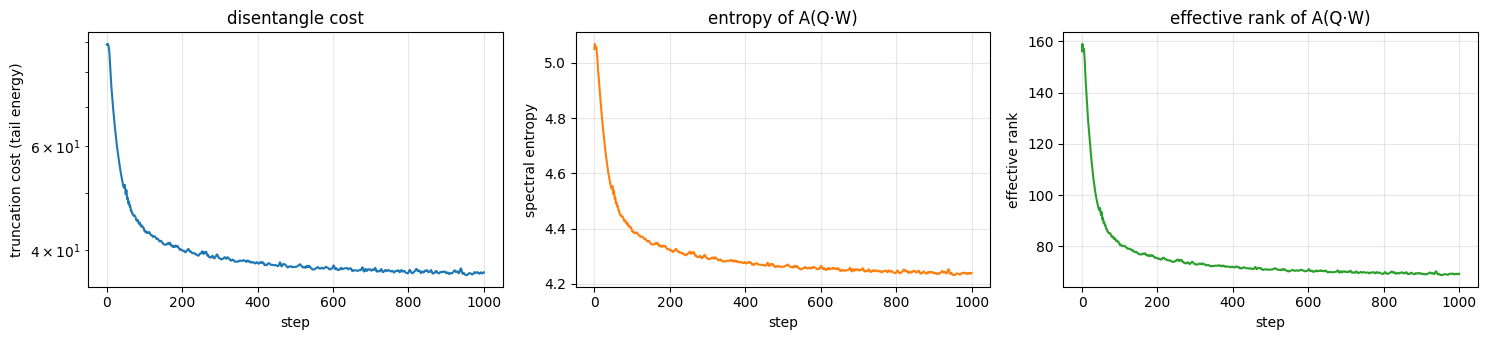

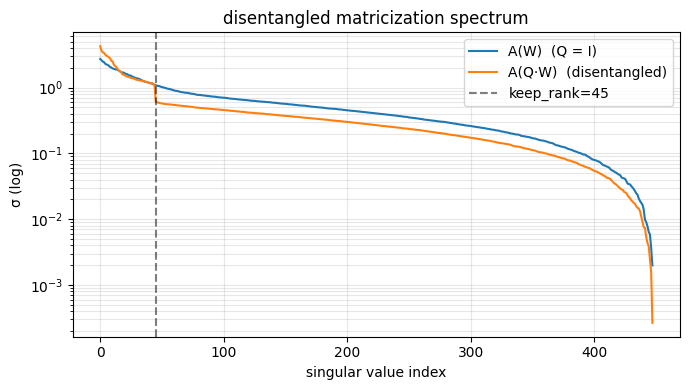

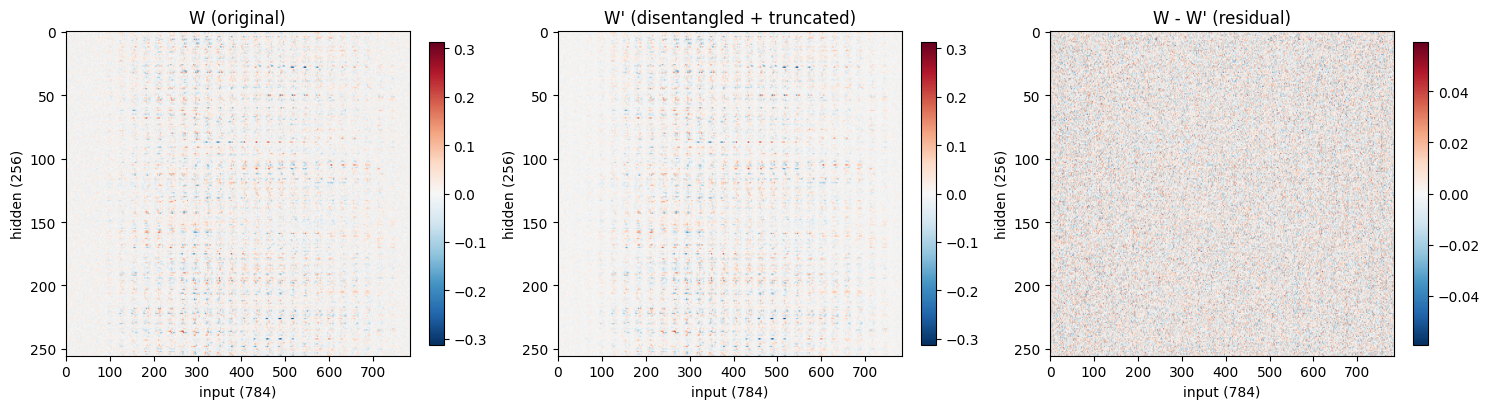

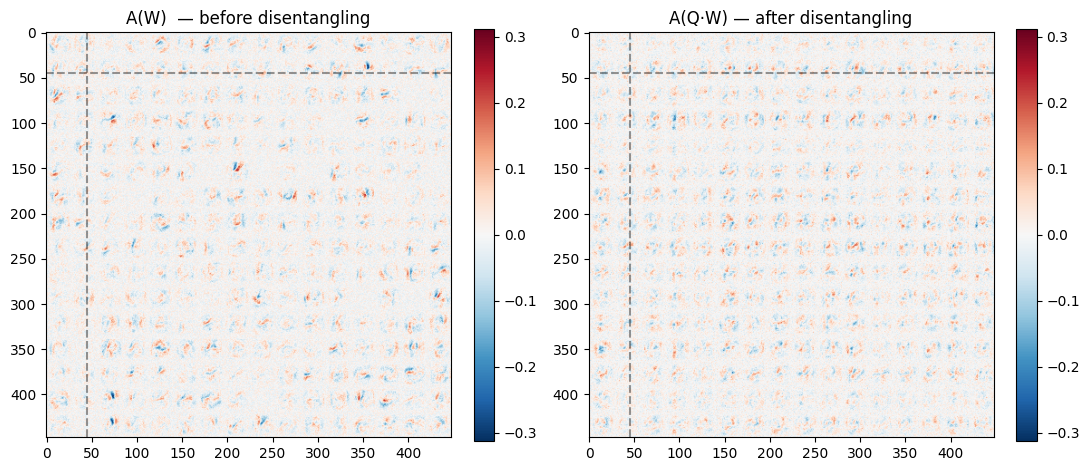

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# ---- training curves of the disentanglement itself ----
hist = inner.history
steps_h = [h["step"] for h in hist]
cost_h = [h["cost"] for h in hist]
ent_h = [h["entropy"] for h in hist]
er_h = [h["effective_rank"] for h in hist]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(steps_h, cost_h)
axes[0].set_yscale("log")
axes[0].set_xlabel("step"); axes[0].set_ylabel("truncation cost (tail energy)"); axes[0].set_title("disentangle cost")
axes[0].grid(alpha=0.3)
axes[1].plot(steps_h, ent_h, color="tab:orange")
axes[1].set_xlabel("step"); axes[1].set_ylabel("spectral entropy"); axes[1].set_title("entropy of A(Q·W)")
axes[1].grid(alpha=0.3)
axes[2].plot(steps_h, er_h, color="tab:green")
axes[2].set_xlabel("step"); axes[2].set_ylabel("effective rank"); axes[2].set_title("effective rank of A(Q·W)")
axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ---- singular value spectra: A(W) vs A(Q·W), with truncation cutoff ----
A_W = DB._apply_A(W64, shape_tuple)
A_QW = DB._apply_A(QW, shape_tuple)
sv_before = torch.linalg.svdvals(A_W).cpu().numpy()
sv_after = torch.linalg.svdvals(A_QW).cpu().numpy()

plt.figure(figsize=(7, 4))
plt.semilogy(sv_before, label="A(W)  (Q = I)")
plt.semilogy(sv_after, label="A(Q·W)  (disentangled)")
plt.axvline(keep_rank, ls="--", color="k", alpha=0.5, label=f"keep_rank={keep_rank}")
plt.xlabel("singular value index"); plt.ylabel("σ (log)")
plt.title("disentangled matricization spectrum")
plt.legend(); plt.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

# ---- weight heatmaps: W, W', and the residual ----
def _sym_lim(*arrs):
    return max(float(np.abs(a).max()) for a in arrs)

W_np = W.cpu().numpy()
Wp_np = W_prime.cpu().numpy()
resid = W_np - Wp_np
vlim = _sym_lim(W_np, Wp_np)
rlim = _sym_lim(resid)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, mat, title, lim in [
    (axes[0], W_np, "W (original)", vlim),
    (axes[1], Wp_np, "W' (disentangled + truncated)", vlim),
    (axes[2], resid, "W - W' (residual)", rlim),
]:
    im = ax.imshow(mat, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_title(title); ax.set_xlabel("input (784)"); ax.set_ylabel("hidden (256)")
    plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()

# ---- disentangled matricization heatmaps: A(W) vs A(Q·W) ----
A_W_np = A_W.cpu().numpy()
A_QW_np = A_QW.cpu().numpy()
alim = _sym_lim(A_W_np, A_QW_np)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, mat, title in [
    (axes[0], A_W_np, "A(W)  — before disentangling"),
    (axes[1], A_QW_np, "A(Q·W) — after disentangling"),
]:
    im = ax.imshow(mat, cmap="RdBu_r", vmin=-alim, vmax=alim)
    ax.axhline(keep_rank, color="k", ls="--", alpha=0.4)
    ax.axvline(keep_rank, color="k", ls="--", alpha=0.4)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

In [6]:
import math

class DisentangledLinear(nn.Module):
    """Linear layer parameterized as  y = (Q^T · A^{-1}(U · diag(s) · V^T)) x + b.

    A is the reshape (l, r, b, c) -> (l*c, r*b) from the disentanglement code.
    Q is a free (out, out) matrix; we don't enforce orthogonality during training
    since it's just one of several factors and gradient flow handles it.
    """
    def __init__(self, in_features, out_features, keep_rank, shape_4d):
        super().__init__()
        l, r, b, c = shape_4d
        assert l * r == out_features and b * c == in_features
        self.shape_4d = shape_4d
        self.k = keep_rank
        self.Q = nn.Parameter(torch.eye(out_features))
        self.U = nn.Parameter(torch.empty(l * c, keep_rank))
        self.s = nn.Parameter(torch.empty(keep_rank))
        self.V = nn.Parameter(torch.empty(r * b, keep_rank))
        self.bias = nn.Parameter(torch.empty(out_features))
        self._init_random(in_features, out_features)

    def _init_random(self, in_f, out_f):
        # Sample a kaiming-uniform dense weight, project it onto the rank-k
        # disentangled subspace via truncated SVD. Gives scratch training a
        # sensible starting scale.
        with torch.no_grad():
            W_init = torch.empty(out_f, in_f)
            nn.init.kaiming_uniform_(W_init, a=math.sqrt(5))
            l, r, b, c = self.shape_4d
            W_perm = W_init.reshape(l, r, b, c).permute(0, 3, 1, 2).reshape(l * c, r * b)
            Ui, Si, Vhi = torch.linalg.svd(W_perm, full_matrices=False)
            self.U.copy_(Ui[:, :self.k])
            self.s.copy_(Si[:self.k])
            self.V.copy_(Vhi[:self.k].t())
            bound = 1 / math.sqrt(in_f)
            nn.init.uniform_(self.bias, -bound, bound)

    @classmethod
    def from_disentangled(cls, in_features, out_features, keep_rank, shape_4d, Q, U, S, Vh, bias):
        layer = cls(in_features, out_features, keep_rank, shape_4d)
        with torch.no_grad():
            layer.Q.copy_(Q.to(torch.float32))
            layer.U.copy_(U[:, :keep_rank].to(torch.float32))
            layer.s.copy_(S[:keep_rank].to(torch.float32))
            layer.V.copy_(Vh[:keep_rank].t().to(torch.float32))
            layer.bias.copy_(bias)
        return layer

    def materialize_weight(self):
        l, r, b, c = self.shape_4d
        M_perm = (self.U * self.s) @ self.V.t()                       # (l*c, r*b)
        M = M_perm.reshape(l, c, r, b).permute(0, 2, 3, 1).reshape(l * r, b * c)
        return self.Q.t() @ M

    def forward(self, x):
        return torch.nn.functional.linear(x, self.materialize_weight(), self.bias)


def build_disent_model(layer1):
    return nn.Sequential(nn.Flatten(), layer1, nn.ReLU(), nn.Linear(hidden, 10))


def train(model, label, n_epochs=10, lr=0.1):
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    tr, vl, accs = [], [], []
    for epoch in range(1, n_epochs + 1):
        model.train()
        rl = 0.0
        for img, lab in train_loader:
            opt.zero_grad()
            loss = criterion(model(img), lab)
            loss.backward()
            opt.step()
            rl += loss.item() * img.size(0)
        train_loss = rl / len(train_ds)
        model.eval()
        corr = 0; vlsum = 0.0
        with torch.no_grad():
            for img, lab in test_loader:
                logits = model(img)
                vlsum += criterion(logits, lab).item() * img.size(0)
                corr += (logits.argmax(1) == lab).sum().item()
        tr.append(train_loss); vl.append(vlsum / len(test_ds)); accs.append(corr / len(test_ds))
        print(f"[{label}] epoch {epoch:2d}  train {tr[-1]:.4f}  val {vl[-1]:.4f}  acc {accs[-1]:.4f}")
    return tr, vl, accs


n_params_dense = sum(p.numel() for p in model[1].parameters())
_tmp = DisentangledLinear(784, hidden, keep_rank, shape_tuple)
n_params_disent = sum(p.numel() for p in _tmp.parameters())
print(f"dense Linear params:        {n_params_dense}")
print(f"DisentangledLinear params:  {n_params_disent}  ({n_params_disent / n_params_dense:.1%} of dense)")

dense Linear params:        200960
DisentangledLinear params:  106157  (52.8% of dense)


In [7]:
# Fine-tune from the disentangled init (reuses Q, U, S, Vh, bias from the trained model).
torch.manual_seed(0)
layer_ft = DisentangledLinear.from_disentangled(
    784, hidden, keep_rank, shape_tuple,
    Q=Q, U=U, S=S, Vh=Vh, bias=model[1].bias.detach(),
)
model_ft = build_disent_model(layer_ft)
with torch.no_grad():
    model_ft[3].weight.copy_(model[3].weight)
    model_ft[3].bias.copy_(model[3].bias)

# Sanity: at init the materialized W should equal W_prime.
err = float((layer_ft.materialize_weight().detach() - W_prime).norm() / W_prime.norm())
print(f"materialized W vs W_prime relative error at init: {err:.2e}")

ft_tr, ft_vl, ft_acc = train(model_ft, "finetune", n_epochs=10, lr=0.05)


# Train from scratch with the same structured layer (random init, fresh probe).
torch.manual_seed(1)
layer_sc = DisentangledLinear(784, hidden, keep_rank, shape_tuple)
model_sc = build_disent_model(layer_sc)
sc_tr, sc_vl, sc_acc = train(model_sc, "scratch ", n_epochs=10, lr=0.1)

materialized W vs W_prime relative error at init: 3.28e-07
[finetune] epoch  1  train 0.0762  val 0.0910  acc 0.9719
[finetune] epoch  2  train 0.0603  val 0.0895  acc 0.9716
[finetune] epoch  3  train 0.0521  val 0.0702  acc 0.9787
[finetune] epoch  4  train 0.0437  val 0.0741  acc 0.9781
[finetune] epoch  5  train 0.0388  val 0.0751  acc 0.9771
[finetune] epoch  6  train 0.0343  val 0.0669  acc 0.9802
[finetune] epoch  7  train 0.0311  val 0.0749  acc 0.9793
[finetune] epoch  8  train 0.0258  val 0.0747  acc 0.9786
[finetune] epoch  9  train 0.0234  val 0.0711  acc 0.9802
[finetune] epoch 10  train 0.0202  val 0.0794  acc 0.9785
[scratch ] epoch  1  train 0.4990  val 0.2136  acc 0.9368
[scratch ] epoch  2  train 0.1774  val 0.1358  acc 0.9589
[scratch ] epoch  3  train 0.1192  val 0.1072  acc 0.9682
[scratch ] epoch  4  train 0.0920  val 0.0908  acc 0.9731
[scratch ] epoch  5  train 0.0762  val 0.0925  acc 0.9715
[scratch ] epoch  6  train 0.0635  val 0.0851  acc 0.9728
[scratch ] ep

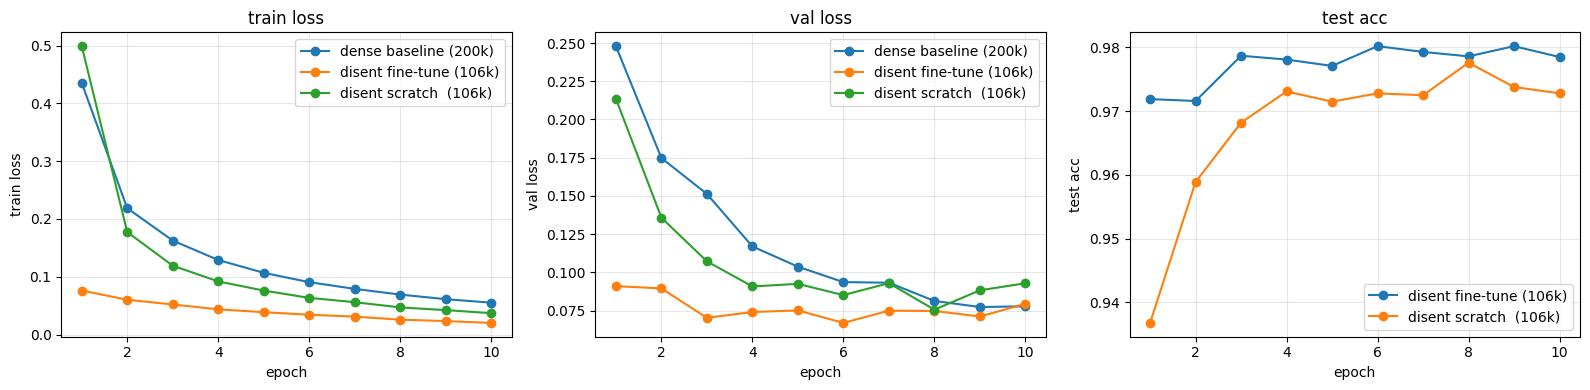

final test acc -- dense baseline: 0.9772  frankenstein (no ft): 0.9765  disent fine-tune: 0.9785  disent scratch: 0.9728


In [8]:
ep = range(1, n_epochs + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (key, ylabel, dense, ft, sc) in zip(
    axes,
    [
        ("train loss", "train loss", train_losses, ft_tr, sc_tr),
        ("val loss",   "val loss",   val_losses,   ft_vl, sc_vl),
        ("test acc",   "test acc",   None,         ft_acc, sc_acc),
    ],
):
    if dense is not None:
        ax.plot(ep, dense, marker="o", label="dense baseline (200k)")
    ax.plot(ep, ft, marker="o", label=f"disent fine-tune ({n_params_disent//1000}k)")
    ax.plot(ep, sc, marker="o", label=f"disent scratch  ({n_params_disent//1000}k)")
    ax.set_xlabel("epoch"); ax.set_ylabel(ylabel); ax.set_title(key)
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

print(f"final test acc -- dense baseline: {test_acc:.4f}  "
      f"frankenstein (no ft): {correct/len(test_ds):.4f}  "
      f"disent fine-tune: {ft_acc[-1]:.4f}  "
      f"disent scratch: {sc_acc[-1]:.4f}")

small dense Linear(784,135) layer-1 params: 105975  vs disent: 106157
[small   ] epoch  1  train 0.4434  val 0.2506  acc 0.9308
[small   ] epoch  2  train 0.2217  val 0.1774  acc 0.9493
[small   ] epoch  3  train 0.1664  val 0.1415  acc 0.9580
[small   ] epoch  4  train 0.1344  val 0.1324  acc 0.9608
[small   ] epoch  5  train 0.1122  val 0.1078  acc 0.9684
[small   ] epoch  6  train 0.0965  val 0.0993  acc 0.9706
[small   ] epoch  7  train 0.0850  val 0.0967  acc 0.9700
[small   ] epoch  8  train 0.0756  val 0.0892  acc 0.9722
[small   ] epoch  9  train 0.0679  val 0.0814  acc 0.9759
[small   ] epoch 10  train 0.0615  val 0.0817  acc 0.9751


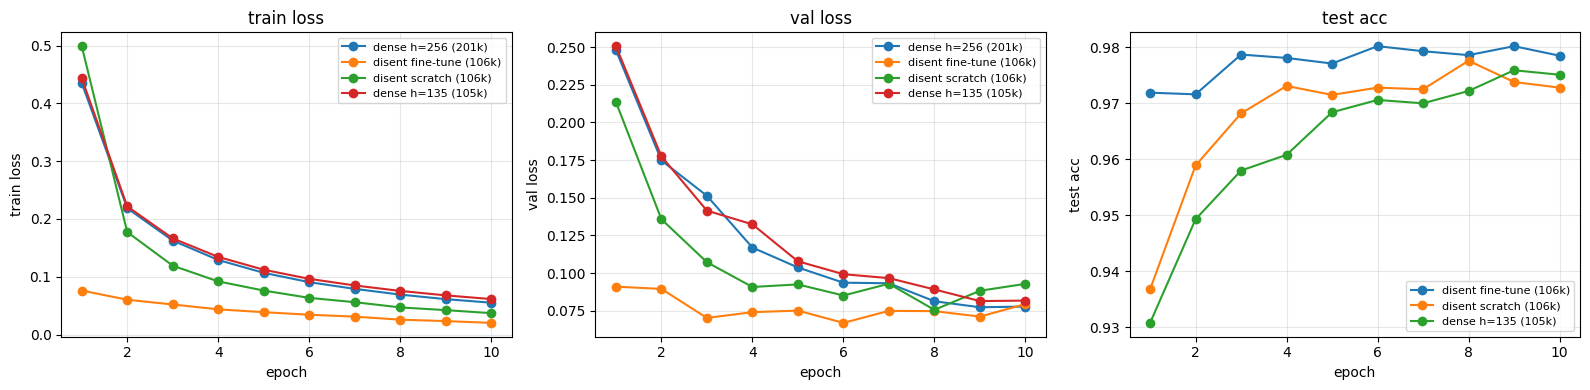

final acc -- dense h=256: 0.9772  disent ft: 0.9785  disent scratch: 0.9728  dense h=135: 0.9751


In [9]:
# Plain dense Linear(784, h) with h chosen so layer-1 params ~= DisentangledLinear (106k).
hidden_small = 135  # 784*135 + 135 = 106,055 ~= 106,157
torch.manual_seed(2)
model_small = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, hidden_small),
    nn.ReLU(),
    nn.Linear(hidden_small, 10),
)
n_params_small = sum(p.numel() for p in model_small[1].parameters())
print(f"small dense Linear(784,{hidden_small}) layer-1 params: {n_params_small}  vs disent: {n_params_disent}")
sm_tr, sm_vl, sm_acc = train(model_small, "small   ", n_epochs=10, lr=0.1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (title, ylabel, dense, ft, sc, sm) in zip(
    axes,
    [
        ("train loss", "train loss", train_losses, ft_tr, sc_tr, sm_tr),
        ("val loss",   "val loss",   val_losses,   ft_vl, sc_vl, sm_vl),
        ("test acc",   "test acc",   None,         ft_acc, sc_acc, sm_acc),
    ],
):
    if dense is not None:
        ax.plot(ep, dense, marker="o", label="dense h=256 (201k)")
    ax.plot(ep, ft, marker="o", label=f"disent fine-tune ({n_params_disent//1000}k)")
    ax.plot(ep, sc, marker="o", label=f"disent scratch ({n_params_disent//1000}k)")
    ax.plot(ep, sm, marker="o", label=f"dense h={hidden_small} ({n_params_small//1000}k)")
    ax.set_xlabel("epoch"); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(
    f"final acc -- dense h=256: {test_acc:.4f}  "
    f"disent ft: {ft_acc[-1]:.4f}  "
    f"disent scratch: {sc_acc[-1]:.4f}  "
    f"dense h={hidden_small}: {sm_acc[-1]:.4f}"
)